# EDA na Prática — Travel Agency Data



## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Convenção de cor (mesma lógica da Aula 11): cinza para "pano de fundo" genérico,
# e o par contexto/destaque para comparações com a variável-alvo (is_booking).
COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"   # rosa-claro: "Não Reservou" (classe de referência)
COR_DESTAQUE = "#2d223a"   # roxo: "Reservou" (classe de interesse)
COR_ALERTA = "tab:red"     # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
import kagglehub
import os

path = kagglehub.dataset_download("nhatnguyentran/travel-agency-data")

df = pd.read_csv(os.path.join(path, 'travel.csv'))

print(df.shape)
df.head()

100%|██████████| 3.96M/3.96M [00:02<00:00, 1.48MB/s]

Extracting files...


(100000, 25)


,Unnamed: 0,date_time,site_name,posa_continent,user_location_country,user_location_region,user_location_city,orig_destination_distance,user_id,is_mobile,...,srch_children_cnt,srch_rm_cnt,srch_destination_id,srch_destination_type_id,is_booking,cnt,hotel_continent,hotel_country,hotel_market,hotel_cluster
0,24636210,2014-11-03 16:02:28,24,2,77,871,36643,456.1151,792280,0,...,0,1,8286,1,0,1,0,63,1258,68
1,19837144,2013-03-13 19:25:01,11,3,205,135,38749,232.4737,961995,0,...,0,1,1842,3,0,1,2,198,786,37
2,13066459,2014-10-13 13:20:25,2,3,66,314,48562,4468.2720,495669,0,...,0,1,8746,1,0,1,6,105,29,22
3,4691082,2013-11-05 10:40:34,11,3,205,411,52752,171.6021,106611,0,...,0,1,6210,3,1,1,2,198,1234,42
4,4878884,2014-06-10 13:34:56,2,3,66,174,50644,NaN,596177,0,...,1,1,12812,5,0,1,2,50,368,83


## 1. Princípio Estrutural

Antes de qualquer análise, entender a "anatomia" dos dados: quantas linhas/colunas, tipos de cada coluna, ausentes e duplicadas.

### Dimensão e Tipos de Dados

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Unnamed: 0                 100000 non-null  int64  
 1   date_time                  100000 non-null  object 
 2   site_name                  100000 non-null  int64  
 3   posa_continent             100000 non-null  int64  
 4   user_location_country      100000 non-null  int64  
 5   user_location_region       100000 non-null  int64  
 6   user_location_city         100000 non-null  int64  
 7   orig_destination_distance  63915 non-null   float64
 8   user_id                    100000 non-null  int64  
 9   is_mobile                  100000 non-null  int64  
 10  is_package                 100000 non-null  int64  
 11  channel                    100000 non-null  int64  
 12  srch_ci                    99878 non-null   object 
 13  srch_co                    998

In [4]:
df.describe()

,Unnamed: 0,site_name,posa_continent,user_location_country,user_location_region,user_location_city,orig_destination_distance,user_id,is_mobile,is_package,...,srch_children_cnt,srch_rm_cnt,srch_destination_id,srch_destination_type_id,is_booking,cnt,hotel_continent,hotel_country,hotel_market,hotel_cluster
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,63915.000000,1.000000e+05,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.882530e+07,9.838570,2.678150,85.995070,308.636990,27676.391240,1960.661721,6.054383e+05,0.133770,0.248140,...,0.336750,1.111750,14426.32738,2.577290,0.079930,1.487980,3.150920,81.093290,598.848330,49.860370
std,1.086183e+07,11.996426,0.749018,59.292002,208.706581,16768.647409,2228.153377,3.516154e+05,0.340407,0.431936,...,0.734449,0.451602,11036.98122,2.149263,0.271186,1.280262,1.620534,56.111519,510.959297,28.885423
min,1.012000e+03,2.000000,0.000000,0.000000,0.000000,0.000000,0.005600,1.400000e+01,0.000000,0.000000,...,0.000000,0.000000,4.00000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,9.448967e+06,2.000000,3.000000,66.000000,174.000000,12949.000000,312.792100,2.987962e+05,0.000000,0.000000,...,0.000000,1.000000,8267.00000,1.000000,0.000000,1.000000,2.000000,50.000000,158.000000,25.000000
50%,1.881212e+07,2.000000,3.000000,66.000000,314.000000,27655.000000,1131.835300,6.028825e+05,0.000000,0.000000,...,0.000000,1.000000,9145.00000,1.000000,0.000000,1.000000,2.000000,50.000000,591.000000,49.000000
75%,2.825307e+07,15.000000,3.000000,70.000000,385.000000,42328.000000,2542.359350,9.157222e+05,0.000000,0.000000,...,0.000000,1.000000,18784.00000,5.000000,0.000000,2.000000,4.000000,106.000000,701.000000,73.000000
max,3.767009e+07,53.000000,4.000000,239.000000,1025.000000,56507.000000,11965.376100,1.198783e+06,1.000000,1.000000,...,9.000000,8.000000,65035.00000,9.000000,1.000000,120.000000,6.000000,212.000000,2117.000000,99.000000


**Pergunta:** o tamanho da base (100 mil linhas, bem maior que os ~300 pacientes do exemplo de Heart Disease) muda como devemos confiar nos testes estatísticos mais adiante?

 **Discussão:** o dataset tem 100.000 linhas e 25 colunas — bem mais que os ~300 pacientes do exemplo de Heart Disease. Isso muda duas coisas mais adiante: testes como o Qui-Quadrado ficam mais confiáveis (mais casos por célula da tabela), mas o Shapiro-Wilk fica *sensível demais* (ele rejeita normalidade mesmo para desvios pequenos quando N é grande — retomamos esse ponto na Seção 3).

A maioria das colunas já vem como `int64`, mas boa parte delas são **códigos categóricos** (IDs), não quantidades de fato: `site_name`, `posa_continent`, `user_location_country/region/city`, `srch_destination_id`, `hotel_continent/country/market/cluster`. As únicas variáveis genuinamente quantitativas são `orig_destination_distance`, `srch_adults_cnt`, `srch_children_cnt`, `srch_rm_cnt` e `cnt`. `date_time`, `srch_ci` e `srch_co` vieram como texto (`object`) em vez de datas — não convertemos porque não é o foco desta análise, mas seria um passo natural de limpeza antes de qualquer modelagem.

### Duplicadas

In [5]:
df.duplicated().sum()

np.int64(0)

Não há linhas duplicadas.

## 2. Dados Faltantes

In [6]:
df.isna().sum()

,0
Unnamed: 0,0
date_time,0
site_name,0
posa_continent,0
user_location_country,0
user_location_region,0
user_location_city,0
orig_destination_distance,36085
user_id,0
is_mobile,0


**Pergunta:** quais colunas têm dados ausentes, e dá pra tratar todas do mesmo jeito?

 **Discussão:** três colunas têm valores ausentes: `orig_destination_distance` (36.085 linhas, **36,1%**), `srch_ci` (122, 0,12%) e `srch_co` (122, 0,12%). A escala é bem diferente do exemplo de Heart Disease (`ca`/`thal`, ~2% cada): aqui, `orig_destination_distance` perde mais de um terço das linhas se simplesmente descartarmos — então a decisão de tratamento não pode ser a mesma "remover e seguir em frente" usada na demonstração.

### Conhecimento de Domínio

* **`orig_destination_distance`** — distância entre a origem inferida da busca (tipicamente geolocalização por IP) e o destino. Não é algo que o usuário digita; é **calculada** pelo sistema. Pode ficar ausente quando o provedor não consegue geolocalizar a origem com confiança (IP corporativo/VPN, parceiro que não repassa geolocalização) — uma limitação do pipeline de coleta, não do comportamento do viajante.
* **`srch_ci` / `srch_co`** (datas de check-in/check-out) — provavelmente ficam ausentes quando o usuário faz uma busca exploratória, sem datas definidas ainda (só olhando destinos/preços, sem intenção imediata de reservar).

*Como os dados foram coletados:* é um log de comportamento de busca em um site de viagens (Expedia), agregando buscas de diferentes pontos de venda (`posa_continent`) e canais de marketing (`channel`) — ou seja, plataformas/integrações diferentes, que podem ter pipelines de coleta diferentes entre si. Isso é uma pista importante para o mecanismo de ausência, que exploramos abaixo.

### As ausências ocorrem juntas?

In [7]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['orig_destination_distance', 'srch_ci', 'srch_co']
orig_destination_distance    36085
srch_ci                        122
srch_co                        122
dtype: int64


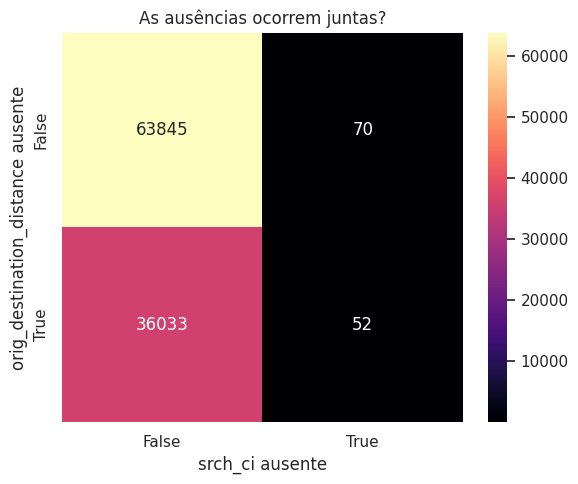

In [8]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Nota:** como temos *três* colunas com ausentes (não duas, como no exemplo da aula), uma única tabela de contingência não conta a história toda. Complementamos com (1) quantas colunas faltam por linha, ao mesmo tempo, e (2) se `srch_ci` e `srch_co` faltam sempre juntas.

In [9]:
linhas_faltantes_por_col = df[cols_com_ausentes].isna().sum(axis=1)
print("Quantas dessas 3 colunas faltam, por linha:")
print(linhas_faltantes_por_col.value_counts().sort_index())

print()
mesma_linha = (df["srch_ci"].isna() == df["srch_co"].isna()).all()
print("srch_ci e srch_co sempre ausentes juntas?", mesma_linha)

Quantas dessas 3 colunas faltam, por linha:
0    63845
1    36033
2       70
3       52
Name: count, dtype: int64

srch_ci e srch_co sempre ausentes juntas? True


**Discussão:** `srch_ci` e `srch_co` estão ausentes **exatamente nas mesmas 122 linhas** — faz sentido de domínio: se a busca não tem data de check-in, também não tem check-out (é a mesma busca "sem datas definidas").

Já a relação entre `orig_destination_distance` ausente e `srch_ci`/`srch_co` ausente é mais sutil: das 122 linhas sem `srch_ci`, 52 (43%) também não têm `orig_destination_distance` — mais que os ~44 esperados por acaso puro (36.085/100.000 × 122). Só que, rodando um teste Qui-Quadrado de independência nessa tabela 2×2, χ² = 1,99 e p = 0,16 — **não rejeitamos a hipótese de independência a 5%**. Ou seja, apesar do pequeno excesso observado, a diferença não é estatisticamente significativa: as duas ausências parecem, de fato, eventos praticamente independentes, não um padrão sistemático conjunto.

### Mecanismo de Ausência

A ausência de `srch_ci`/`srch_co` (volume pequeno, sem padrão claro com outras colunas) tem cara de **MCAR/MAR** — provavelmente ligada a decisões pontuais do usuário (busca sem data definida), não a um viés sistemático.

Para `orig_destination_distance`, o volume é grande demais (36%) para ser só "ruído" — vale testar se a ausência está associada a variáveis *observadas* (o que caracterizaria MAR) em vez de ao próprio valor da distância (MNAR).

In [10]:
from scipy.stats import chi2_contingency

df["dist_ausente"] = df["orig_destination_distance"].isna()

for col in ["is_mobile", "is_booking", "is_package", "channel", "posa_continent"]:
    tabela = pd.crosstab(df["dist_ausente"], df[col])
    chi2, p, dof, esperado = chi2_contingency(tabela)
    print(f"dist_ausente x {col}: chi2={chi2:.2f}  p={p:.4g}  (dof={dof})")

dist_ausente x is_mobile: chi2=8.04  p=0.004574  (dof=1)
dist_ausente x is_booking: chi2=22.37  p=2.252e-06  (dof=1)
dist_ausente x is_package: chi2=15.88  p=6.763e-05  (dof=1)
dist_ausente x channel: chi2=1020.84  p=6.057e-213  (dof=10)
dist_ausente x posa_continent: chi2=28160.54  p=0  (dof=4)


In [11]:
taxa_ausencia_por_continente = (
    df.groupby("posa_continent")["dist_ausente"]
    .agg(taxa_ausencia="mean", n="count")
)
taxa_ausencia_por_continente["taxa_ausencia"] = (taxa_ausencia_por_continente["taxa_ausencia"] * 100).round(1)
taxa_ausencia_por_continente

,taxa_ausencia,n
posa_continent,,
0,31.6,708
1,73.3,11879
2,96.5,9438
3,22.4,74840
4,39.8,3135


**Pergunta:** a ausência de `orig_destination_distance` parece aleatória, ou está associada a alguma variável que já observamos (o que apontaria pra MAR em vez de MNAR)?

**Discussão:** todas as associações são estatisticamente significativas (p < 0,01), mas a de `posa_continent` (ponto de venda) é *ordens de grandeza* mais forte que as demais (χ² ≈ 28.161 vs. χ² entre 8 e 1.021 nas outras). E olhando a taxa de ausência por continente, o padrão é evidente: no `posa_continent` 2, **96,5%** das linhas não têm distância registrada, contra **22,4%** no `posa_continent` 3 (o mais comum, 75% dos dados).

Isso é uma evidência forte de **MAR**: a ausência não depende do valor da distância em si, mas de uma variável observada — muito provavelmente o ponto de venda/canal usa uma integração (API) que simplesmente não calcula ou não repassa a geolocalização de origem para determinados mercados. Não dá pra confirmar sem acesso ao pipeline real de coleta, mas a concentração é forte demais pra ser coincidência.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes/outliers), calculamos as estatísticas descritivas e olhamos as distribuições. Esse retrato "antes" orienta as decisões de tratamento na próxima seção.

In [12]:
# Variáveis quantitativas do dataset de viagens
VARS_QUANT = [
    "orig_destination_distance",
    "srch_children_cnt",
    "srch_rm_cnt",
    "srch_destination_id",
    "hotel_cluster"
]
# Tabela descritiva
desc = df[VARS_QUANT].describe().T

# Assimetria
desc["skewness"] = df[VARS_QUANT].skew()

# Curtose
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

# Exibir tabela
(
    desc[[
        "mean",
        "50%",
        "std",
        "min",
        "max",
        "skewness",
        "kurtosis"
    ]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style
    .format(precision=2)
    .background_gradient(
        cmap="magma",
        subset=["skewness", "kurtosis"]
    )
)

,mean,median,std,min,max,skewness,kurtosis
orig_destination_distance,1960.66,1131.84,2228.15,0.01,11965.38,1.61,2.14
srch_children_cnt,0.34,0.00,0.73,0.00,9.00,2.49,7.43
srch_rm_cnt,1.11,1.00,0.45,0.00,8.00,6.76,67.88
srch_destination_id,14426.33,9145.00,11036.98,4.00,65035.00,1.92,3.94
hotel_cluster,49.86,49.00,28.89,0.00,99.00,0.00,-1.15


**Pergunta:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` bem acima de 1) ou com cauda pesada (`kurtosis` alta) — e isso é coerente com o que esperaríamos de dados de busca de viagem?

**Discussão:** `srch_destination_id` e `hotel_cluster` são **códigos categóricos** (IDs de destino/cluster de hotel), não quantidades reais — média e assimetria deles não têm interpretação física, então a partir daqui restringimos `VARS_QUANT` às três variáveis que são de fato quantidades: `orig_destination_distance`, `srch_children_cnt` e `srch_rm_cnt`.

Todas as três têm `skewness` bem acima de 1 (1,61 / 2,49 / 6,76) e `kurtosis` alta (2,14 / 7,43 / 67,88) — extremamente assimétricas e com caudas pesadas. Isso já é esperado fisicamente: a maioria das buscas é de casais/famílias pequenas sem filhos (`srch_children_cnt` concentrado em 0) reservando 1 quarto (`srch_rm_cnt` concentrado em 1), com uma cauda longa de grupos maiores — e distâncias de viagem que vão de vizinhas a intercontinentais.

### Distribuições de dados

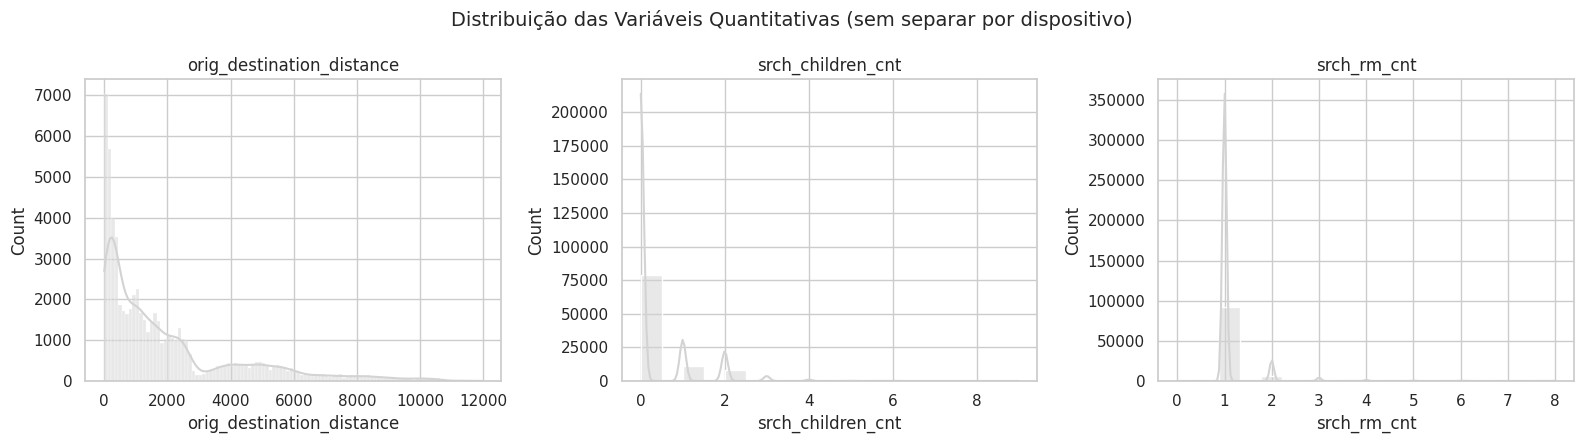

In [13]:
VARS_QUANT = [
    "orig_destination_distance",
    "srch_children_cnt",
    "srch_rm_cnt"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas (sem separar por dispositivo)", fontsize=14)
plt.tight_layout()
plt.show()

Onde fizer sentido, comparamos também **Não Mobile** vs. **Mobile** (`is_mobile`), a mesma variável de segmentação já usada no notebook original.

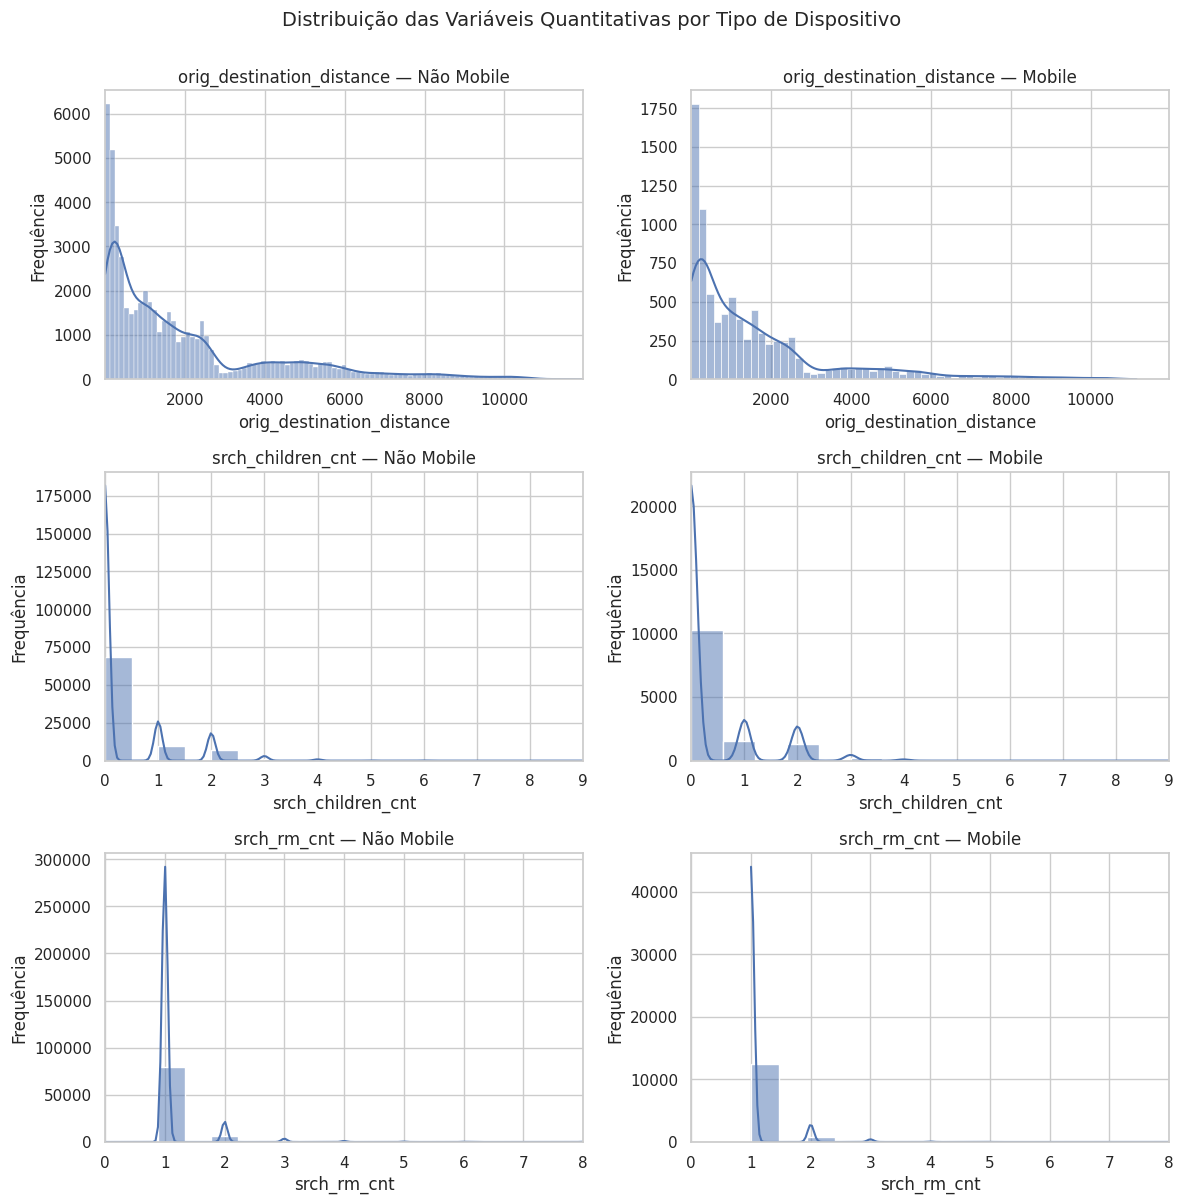

In [14]:
# Criar os painéis
fig, axes = plt.subplots(
    len(VARS_QUANT),
    2,
    figsize=(12, 4 * len(VARS_QUANT)),
    sharey=False
)

for i, col in enumerate(VARS_QUANT):

    # Limites iguais para os dois grupos
    lim = (
        df[col].min(),
        df[col].max()
    )

    # Comparar buscas feitas pelo celular e não celular
    for j, (classe, nome) in enumerate([
        (0, "Não Mobile"),
        (1, "Mobile")
    ]):

        subset = df[df["is_mobile"] == classe]

        sns.histplot(
            data=subset,
            x=col,
            kde=True,
            ax=axes[i, j]
        )

        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(
            f"{col} — {nome}"
        )

        axes[i, j].set_xlabel(col)
        axes[i, j].set_ylabel("Frequência")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas por Tipo de Dispositivo",
    fontsize=14,
    y=1.002
)

plt.tight_layout()
plt.show()

**Pergunta:** o formato da distribuição muda entre buscas Mobile e Não Mobile, ou só a escala (quantidade de buscas)?

**Discussão:** o formato geral (forte assimetria à direita) se mantém em Mobile e Não Mobile para as três variáveis — não há uma mudança de forma óbvia, só de escala (Mobile tem bem menos buscas no total, 13,4% do dataset). `orig_destination_distance` parece um pouco mais concentrada em distâncias curtas no Mobile — condizente com buscas feitas "on the go", perto de onde o usuário já está.

#### Testes de Aderência

*Será que a distância entre origem e destino segue uma distribuição normal?*

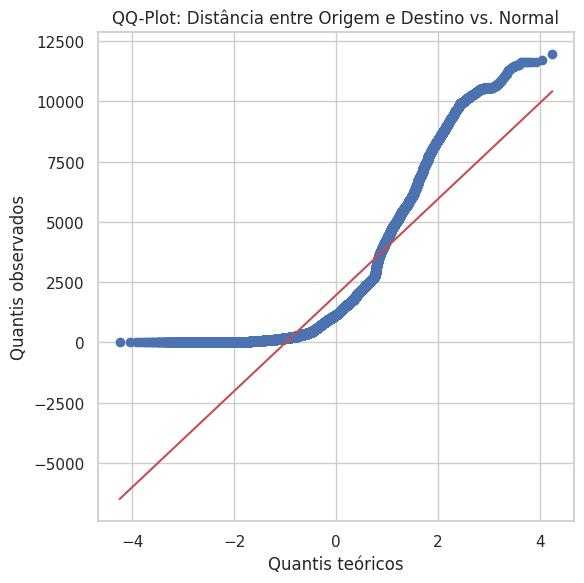

In [15]:
dados = df["orig_destination_distance"].dropna()

fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(
    dados,
    dist="norm",
    plot=ax
)

ax.set_title(
    "QQ-Plot: Distância entre Origem e Destino vs. Normal"
)

ax.set_xlabel("Quantis teóricos")
ax.set_ylabel("Quantis observados")

plt.tight_layout()
plt.show()

**Como ler:** se os pontos seguissem a reta vermelha de perto, a variável seguiria uma normal. Aqui eles se afastam fortemente nas duas pontas — cauda muito mais pesada que a normal, coerente com a assimetria alta já vista na tabela.

In [16]:
# Variáveis quantitativas do dataset
VARS_QUANT = [
    "orig_destination_distance",
    "srch_children_cnt",
    "srch_rm_cnt"
]

# Armazenar os resultados
resultados_shapiro = []

for col in VARS_QUANT:

    # Remove valores ausentes
    dados = df[col].dropna()

    # Teste de Shapiro-Wilk
    stat, p = stats.shapiro(dados)

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

# Criar tabela com os resultados
resultado = pd.DataFrame(resultados_shapiro)

resultado.set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 63915.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 100000.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
orig_destination_distance,0.7998,0.0,True
srch_children_cnt,0.5200,0.0,True
srch_rm_cnt,0.2609,0.0,True


**Nota — cuidado com uma armadilha de interpretação:** com N entre 64 mil e 100 mil (bem maior que os ~300 pacientes do exemplo da aula), o Shapiro-Wilk fica extremamente sensível e rejeitaria a normalidade mesmo para desvios triviais. Mas aqui isso **não** é só um artefato de amostra grande: o QQ-Plot mostra um desvio grande e sistemático (não um leve afastamento nas pontas), e a assimetria já era >1,6 nas três variáveis. Três evidências concordando (skewness alta, QQ-Plot bem afastado da reta, Shapiro-Wilk rejeitando) é um resultado confiável, não um artefato do tamanho da amostra.

A afirmação correta é "há evidência estatística **contra** a normalidade" — uma conclusão forte, já que o teste rejeitou H0 nas três variáveis (p ≈ 0).

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: mostra a proporção acumulada de observações até cada valor. É útil pra comparar dois grupos lado a lado.

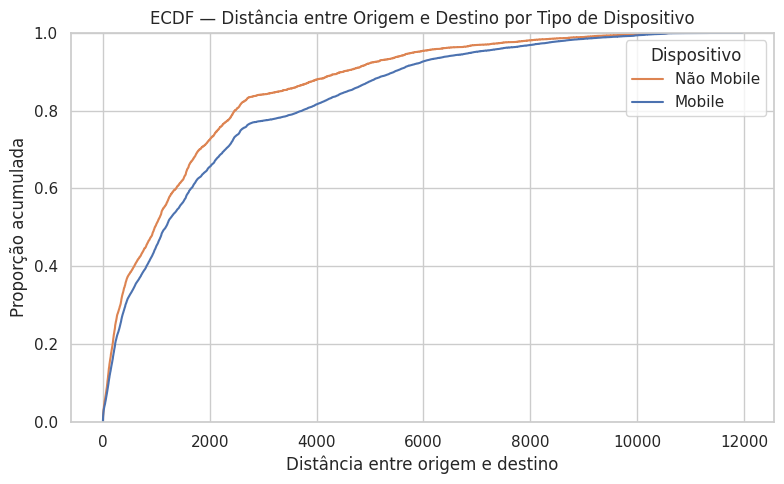

In [17]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df,
    x="orig_destination_distance",
    hue="is_mobile"
)

plt.title(
    "ECDF — Distância entre Origem e Destino por Tipo de Dispositivo"
)

plt.xlabel("Distância entre origem e destino")
plt.ylabel("Proporção acumulada")

plt.legend(
    title="Dispositivo",
    labels=["Não Mobile", "Mobile"]
)

plt.tight_layout()
plt.show()

**Correção em relação à versão original:** a legenda estava com os rótulos trocados (`labels=["Mobile", "Não Mobile"]`, mas o `hue="is_mobile"` ordena as curvas por valor crescente — 0 primeiro, ou seja "Não Mobile" primeiro). Corrigido para `["Não Mobile", "Mobile"]` acima.

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das buscas desse grupo tem distância até aqui". As duas curvas ficam bem próximas — reforça a leitura do histograma: a forma da distribuição não muda muito entre Mobile e Não Mobile.

### Métricas de Tendência Central

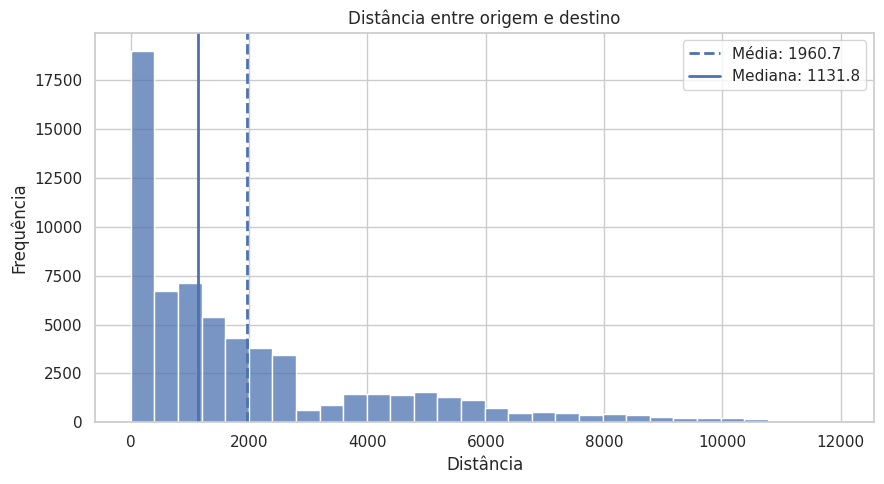

In [18]:
dados = df["orig_destination_distance"].dropna()

media = dados.mean()
mediana = dados.median()

plt.figure(figsize=(9, 5))

sns.histplot(
    dados,
    bins=30
)

plt.axvline(
    media,
    linestyle="--",
    linewidth=2,
    label=f"Média: {media:.1f}"
)

plt.axvline(
    mediana,
    linestyle="-",
    linewidth=2,
    label=f"Mediana: {mediana:.1f}"
)

plt.title("Distância entre origem e destino")
plt.xlabel("Distância")
plt.ylabel("Frequência")
plt.legend()
plt.tight_layout()

plt.show()

**Pergunta:** média e mediana deveriam ser parecidas aqui, ou a assimetria que já vimos faz elas se afastarem?

 **Discussão:** a média (1.960,7) fica bem acima da mediana (1.131,8) — assinatura clássica de distribuição assimétrica à direita: alguns valores muito altos (viagens intercontinentais) puxam a média pra cima, enquanto a mediana (mais robusta a outliers) reflete melhor a "distância típica" de uma busca.

### Dispersão

In [19]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
orig_destination_distance,4964667.47,2228.15,2229.57
srch_children_cnt,0.54,0.73,0.00
srch_rm_cnt,0.20,0.45,0.00


/tmp/ipykernel_1264/2976484358.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, i].set_xticklabels(["Não Mobile", "Mobile"])
/tmp/ipykernel_1264/2976484358.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, i].set_xticklabels(["Não Mobile", "Mobile"])
/tmp/ipykernel_1264/2976484358.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, i].set_xticklabels(["Não Mobile", "Mobile"])
/tmp/ipykernel_1264/2976484358.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, i].set_xticklabels(["Não Mobile", "Mobile"])
/tmp/ipykernel_1264/2976484358.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks

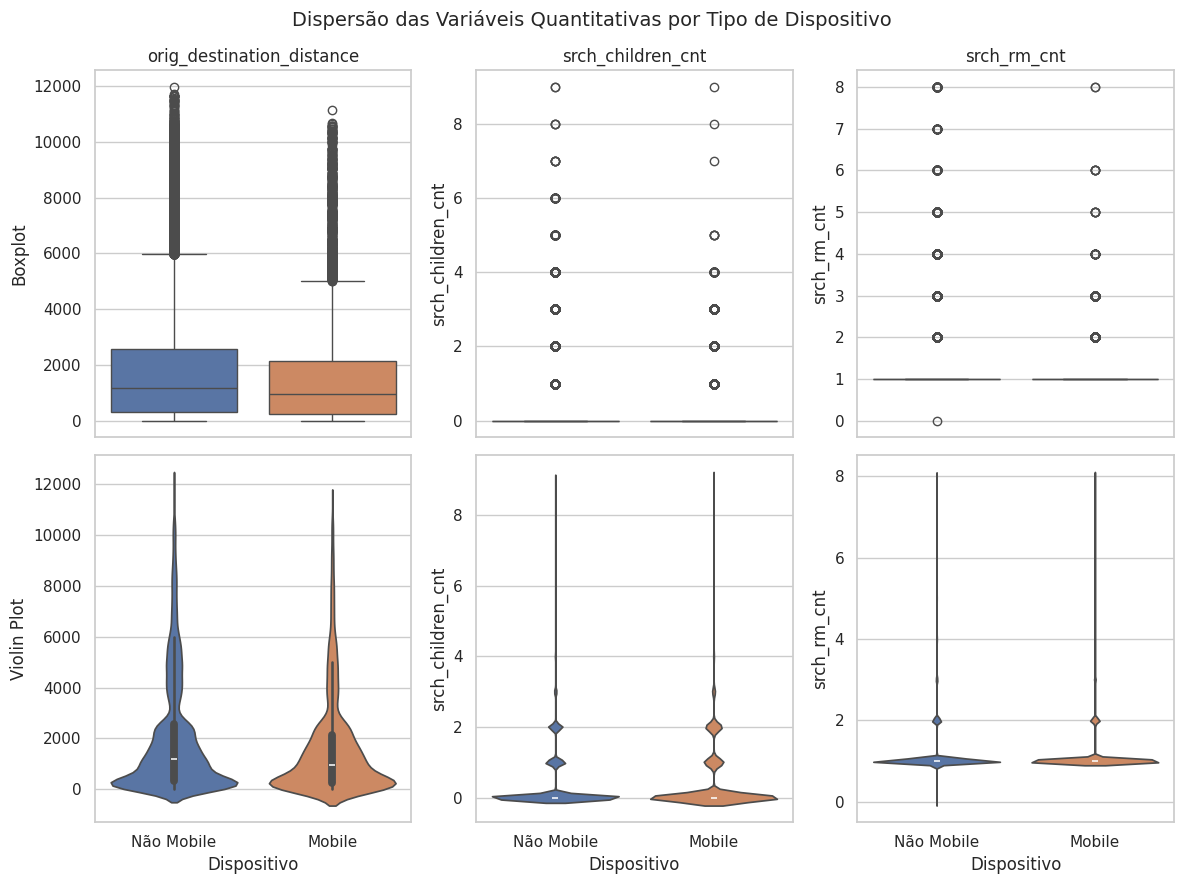

In [20]:
fig, axes = plt.subplots(
    2,
    len(VARS_QUANT),
    figsize=(4 * len(VARS_QUANT), 9),
    sharex="col"
)

for i, col in enumerate(VARS_QUANT):

    # Boxplot
    sns.boxplot(
        data=df,
        x="is_mobile",
        y=col,
        hue="is_mobile",
        legend=False,
        ax=axes[0, i]
    )

    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("Dispositivo")
    axes[0, i].set_xticklabels(["Não Mobile", "Mobile"])

    # Violin plot
    sns.violinplot(
        data=df,
        x="is_mobile",
        y=col,
        hue="is_mobile",
        legend=False,
        ax=axes[1, i]
    )

    axes[1, i].set_xlabel("Dispositivo")
    axes[1, i].set_xticklabels(["Não Mobile", "Mobile"])

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin Plot")

fig.suptitle(
    "Dispersão das Variáveis Quantitativas por Tipo de Dispositivo",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Pergunta:** alguma variável mostra uma dispersão (IQR/boxplot) nitidamente diferente entre Mobile e Não Mobile?

**Discussão:** os violin plots deixam claro que `srch_children_cnt` e `srch_rm_cnt` são praticamente **discretas e concentradas** (a "caixa" do boxplot quase não aparece porque Q1=Q3 na maioria dos casos) — isso vai ser importante na próxima seção, quando olharmos outliers via IQR. `orig_destination_distance` tem caixa/violino bem mais alto em Não Mobile, confirmando o que já víamos no histograma: dispersão maior fora do celular.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato "antes" (Seção 3) em mãos, já temos a informação que faltava pra decidir como tratar ausentes e outliers. Depois do tratamento, rodamos a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [21]:
def limites_iqr(serie):
    serie = serie.dropna()

    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1

    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = {}

for col in VARS_QUANT:

    lim_inf, lim_sup = limites_iqr(df[col])

    dados = df[col].dropna()

    n_outliers = (
        (dados < lim_inf) | (dados > lim_sup)
    ).sum()

    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
orig_destination_distance,-3031.56,5886.71,4778.0
srch_children_cnt,0.00,0.00,21253.0
srch_rm_cnt,1.00,1.00,8327.0


### Visualizando os Outliers

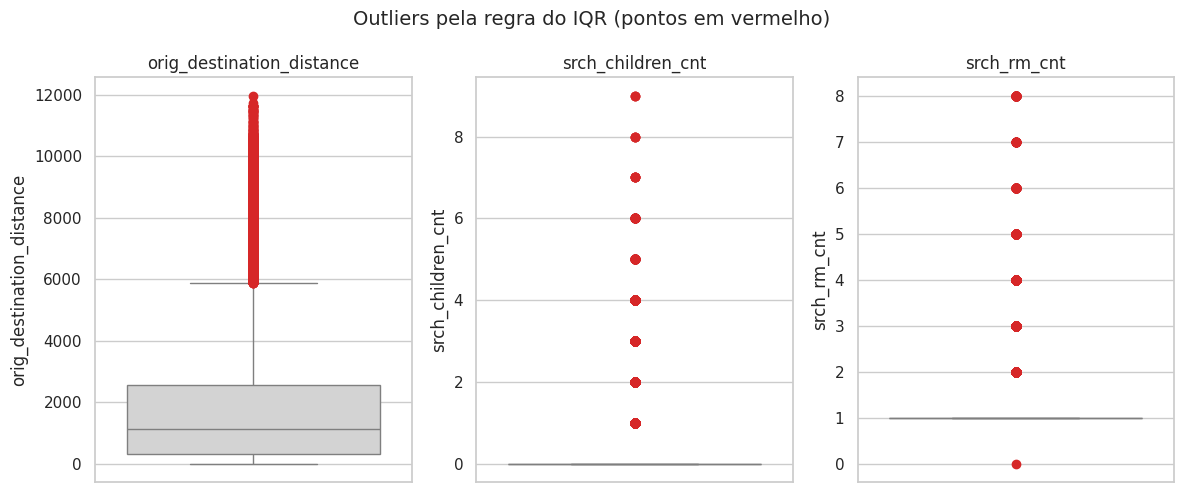

In [22]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pergunta:** os pontos marcados como outlier pelo IQR são valores implausíveis (erro de coleta), casos raros mas reais, ou um artefato do próprio método?

**Discussão — classificando os outliers (estatístico / de domínio / erro de dados):**

* **`orig_destination_distance`** (4.778 outliers, limite superior ≈ 5.887): distâncias de até ~12.000 km são fisicamente plausíveis (viagens intercontinentais são incomuns, mas reais). Classificação: **estatístico/legítimo** → manter (ou transformar, se algum teste paramétrico precisar).
* **`srch_children_cnt`** (21.253 "outliers") e **`srch_rm_cnt`** (8.327 "outliers"): aqui o problema é a **própria regra do IQR**, não os dados. Como já vimos nos violin plots, essas duas variáveis são discretas e fortemente concentradas em um único valor (0 filhos, 1 quarto), então Q1 = Q3 = esse valor, o IQR fica 0, e **qualquer linha que se desvie do valor mais comum é marcada como outlier** — inclusive uma família perfeitamente normal com 1 ou 2 filhos. Isso não é um erro de coleta nem um valor implausível; é uma **limitação conhecida do método IQR em variáveis discretas/muito assimétricas**. Classificação: nenhuma das três categorias do slide se aplica bem — é um **falso positivo do método**, não um outlier de fato.

**Decisão:** não remover outliers de nenhuma das três variáveis. Para `orig_destination_distance`, ilustramos abaixo como ficaria uma transformação logarítmica (útil se, mais adiante, algum teste paramétrico exigir menos assimetria). Para `srch_children_cnt`/`srch_rm_cnt`, a decisão é simplesmente **não aplicar a regra do IQR** como critério de anomalia — os valores "extremos" (ex: 8 quartos, 9 crianças) são raros, mas genuínos.

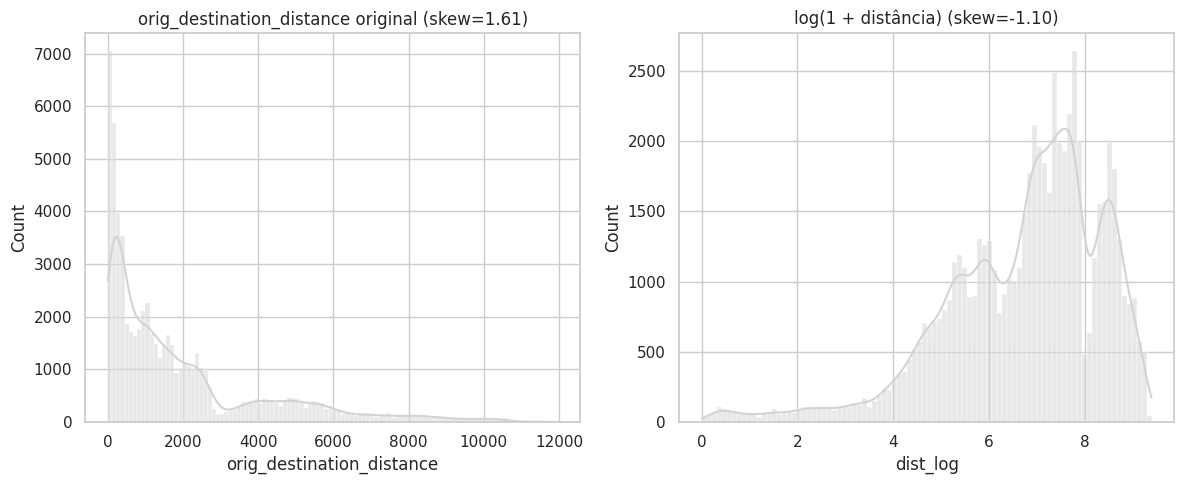

In [23]:
df["dist_log"] = np.log1p(df["orig_destination_distance"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="orig_destination_distance", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"orig_destination_distance original (skew={df['orig_destination_distance'].skew():.2f})")

sns.histplot(data=df, x="dist_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + distância) (skew={df['dist_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pergunta:** a transformação logarítmica deixa `orig_destination_distance` mais próxima de uma normal?

**Discussão:** a transformação log **não** resolveu a assimetria de forma limpa — ela saiu de +1,61 (cauda pesada à direita) para **-1,10** (cauda à esquerda), ou seja, trocou de sinal em vez de convergir pra perto de 0. Olhando o histograma transformado, dá pra ver o motivo: a concentração de distâncias bem pequenas (viagens curtas, perto de 0) vira um platô grande nos valores baixos de `log(1+distância)`, e o log comprime tanto a cauda longa original que ela deixa de "puxar" a média pra cima — só que agora sobra uma cauda fina do lado esquerdo (os valores próximos de zero, já bem comprimidos pelo log). É um lembrete útil: **log não é uma correção automática** — funciona bem quando a assimetria vem só de uma cauda longa, mas aqui a distribuição tem uma concentração adicional perto do mínimo que o log escancara na direção oposta. Mantemos `dist_log` só como demonstração; não a usamos nas próximas seções.

### Decidindo o Tratamento dos Dados Ausentes

Juntando o que já vimos:

* **`srch_ci` / `srch_co`** (122 linhas, 0,12%, sempre ausentes juntas, sem associação forte com outras colunas): volume irrisório e sem indício de viés sistemático → **remover as linhas**. O custo é desprezível (perdemos 0,12% dos dados) e o risco de viés é baixo.
* **`orig_destination_distance`** (36.085 linhas, 36,1%, fortemente associada a `posa_continent`/`channel` → mecanismo **MAR**): remover essas linhas descartaria mais de um terço da base e, pior, descartaria de forma **desigual entre continentes** (quase todo o `posa_continent` 2 desapareceria), distorcendo a representatividade geográfica que sobrar. Imputar com a mediana também é arriscado aqui: para o `posa_continent` 2, a "ausência" não parece ser um buraco de dado — parece ser que aquele canal **não calcula** essa distância; inventar um número pra esses casos criaria uma distância falsa, não preencheria uma real. Por isso, a decisão é **manter os valores ausentes como estão** (excluí-los caso a caso nas análises que precisam da distância, como já vínhamos fazendo com `.dropna()`) e criar uma coluna indicadora (`dist_ausente`) — a própria ausência é uma informação útil (ex: pode servir de proxy de canal/região em uma modelagem futura).

In [24]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df = df.dropna(subset=["srch_ci", "srch_co"]).reset_index(drop=True)
df["dist_ausente"] = df["orig_destination_distance"].isna()

linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")
print(f"orig_destination_distance ainda ausente em {df['dist_ausente'].sum()} linhas "
      f"({df['dist_ausente'].mean():.1%}) — mantido de propósito, ver decisão acima.")

Linhas antes: 100000 | Linhas depois: 99878 | Removidas: 122
orig_destination_distance ainda ausente em 36033 linhas (36.1%) — mantido de propósito, ver decisão acima.


## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: removemos as 122 linhas sem `srch_ci`/`srch_co` e decidimos manter ausentes/outliers de `orig_destination_distance`, `srch_children_cnt` e `srch_rm_cnt` como estão. Rodamos a mesma bateria de estatísticas da Seção 3 para comparar com o "antes".

In [25]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
orig_destination_distance,1960.77,1132.26,2227.83,0.01,11965.38,1.61,2.14
srch_children_cnt,0.34,0.00,0.73,0.00,9.00,2.49,7.42
srch_rm_cnt,1.11,1.00,0.45,0.00,8.00,6.75,67.61


### Comparando "antes" x "depois"

In [26]:
comparacao = pd.DataFrame({
    "skewness_antes": desc.loc[VARS_QUANT, "skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc.loc[VARS_QUANT, "kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
orig_destination_distance,1.606,1.605,2.143,2.142,-0.000,-0.000
srch_children_cnt,2.489,2.488,7.428,7.420,-0.001,-0.008
srch_rm_cnt,6.763,6.748,67.880,67.610,-0.015,-0.270


**Pergunta:** o tratamento (remover 122 linhas, não mexer nos outliers) deveria ter mudado bastante as estatísticas descritivas?

 **Discussão:** os valores praticamente não mudaram. Fazia sentido esperar isso: removemos só 0,12% das linhas e decidimos **não** alterar nenhum outlier nem imputar nada em `orig_destination_distance`. Esse resultado (quase nenhuma mudança) confirma que o tratamento foi conservador por escolha — não que ele não fez nada de útil. Diferente do exemplo de Heart Disease (onde ~2% das linhas foram removidas), aqui a decisão consciente de *não* tratar agressivamente `orig_destination_distance` é o que evita uma mudança maior (e um viés geográfico) nos dados.

In [27]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["orig_destination_distance"].dropna())
print(f"Shapiro-Wilk (antes)  — orig_destination_distance: estatística={resultado.set_index('variavel').loc['orig_destination_distance','estatistica']:.4f}")
print(f"Shapiro-Wilk (depois) — orig_destination_distance: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — orig_destination_distance: estatística=0.7998
Shapiro-Wilk (depois) — orig_destination_distance: estatística=0.7999, p-valor=3.064e-121


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 63845.
  res = hypotest_fun_out(*samples, **kwds)


**O colesterol tinha um equivalente aqui:** assim como no exemplo da aula, a normalidade continua fortemente rejeitada depois do tratamento — nem esperávamos outro resultado, já que não tocamos na forma da distribuição.

**Visualizando antes x depois, lado a lado** (amostra de 5.000 linhas em cada versão, só para deixar o KDE leve).

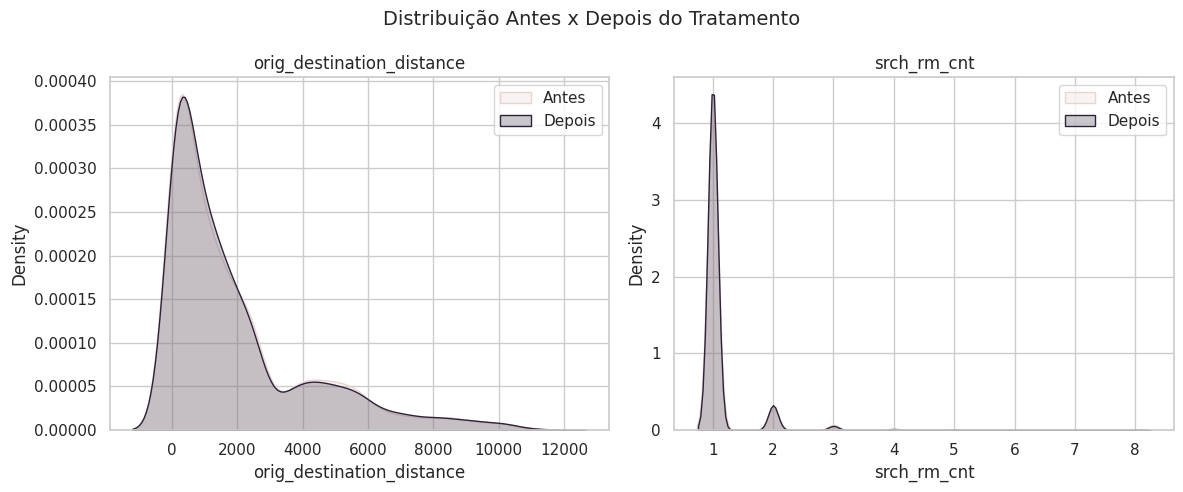

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

amostra_antes = df_antes["orig_destination_distance"].dropna().sample(5000, random_state=42)
amostra_depois = df["orig_destination_distance"].dropna().sample(5000, random_state=42)

for ax, col, s_antes, s_depois in zip(axes, ["orig_destination_distance", "srch_rm_cnt"],
                                        [amostra_antes, df_antes["srch_rm_cnt"].sample(5000, random_state=42)],
                                        [amostra_depois, df["srch_rm_cnt"].sample(5000, random_state=42)]):
    sns.kdeplot(s_antes, color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(s_depois, color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** as curvas "antes" e "depois" praticamente se sobrepõem, como esperado — removemos poucas linhas e não tocamos em outliers. Em um dataset onde o volume de ausentes/outliers tratados fosse maior, essa mesma checagem poderia revelar uma diferença bem mais visível; o valor dela está em **confirmar** o efeito esperado, não em assumir isso às cegas.

## 6. Princípio Relacional

Esta seção não existia na versão original do notebook — é a maior lacuna em relação à demonstração da Aula 11. Aqui avaliamos frequência/desbalanceamento das qualitativas e como as variáveis se relacionam entre si e com o desfecho de interesse.

**Variável-alvo:** como o dataset de viagens não tem um "diagnóstico" como `doenca_cardiaca`, usamos **`is_booking`** (a busca resultou em reserva?) no papel de variável-alvo — é o desfecho de negócio mais natural do dataset.

### Análise de Variáveis Qualitativas

Focamos em colunas categóricas com cardinalidade baixa o suficiente pra fazer sentido em tabelas de frequência e gráficos de barra (excluímos IDs de alta cardinalidade como `user_location_country`, `hotel_market` etc., pelo mesmo motivo que excluímos `srch_destination_id`/`hotel_cluster` das quantitativas — são identificadores, não categorias interpretáveis).

In [29]:
VARS_QUALI = [
    "is_mobile",
    "is_package",
    "channel",
    "posa_continent",
    "srch_destination_type_id",
    "hotel_continent",
    "is_booking",
]

#### Frequências absolutas e relativas

In [30]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- is_mobile ---
           absoluta  relativa
is_mobile                    
0             86529     0.866
1             13349     0.134

--- is_package ---
            absoluta  relativa
is_package                    
0              75079     0.752
1              24799     0.248

--- channel ---
         absoluta  relativa
channel                    
9           55314     0.554
0           12474     0.125
1           10258     0.103
2            7827     0.078
5            6155     0.062
3            4400     0.044
4            2192     0.022
7             810     0.008
8             271     0.003
6             162     0.002
10             15     0.000

--- posa_continent ---
                absoluta  relativa
posa_continent                    
3                  74762     0.749
1                  11868     0.119
2                   9416     0.094
4                   3126     0.031
0                    706     0.007

--- srch_destination_type_id ---
                          absolut

#### Visualizando as frequências

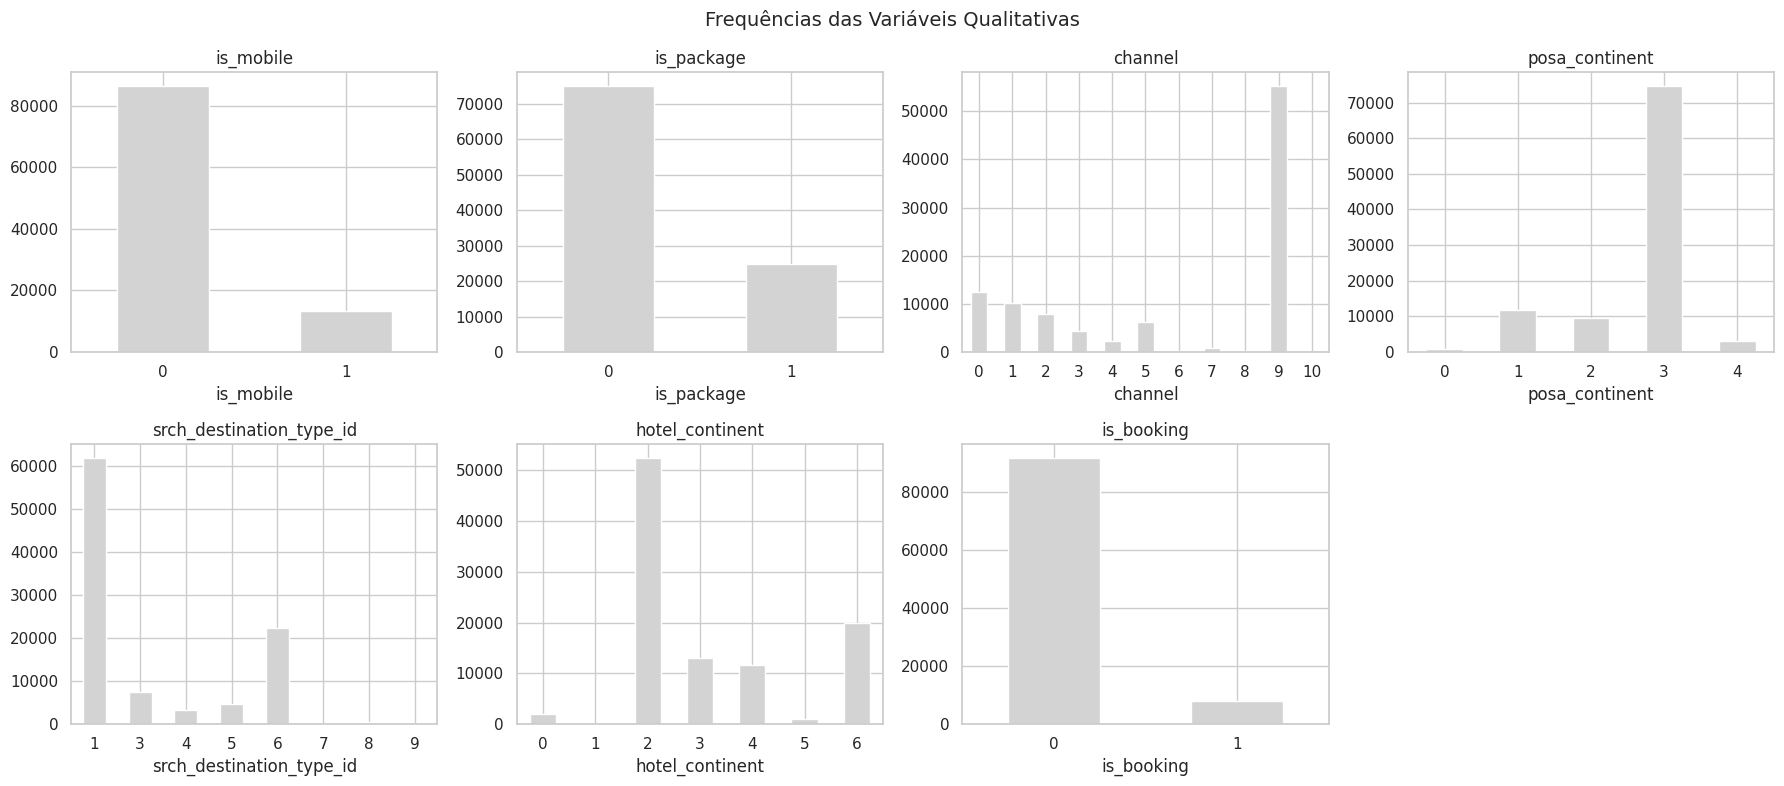

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** `channel` e `is_booking` chamam atenção: `channel` tem uma categoria (9) concentrando mais da metade das buscas e uma (10) com só 15 linhas; `is_booking` é fortemente desbalanceado (a maioria das buscas não vira reserva, o que é normal em dados de navegação/e-commerce). Isso já é um alerta pra qualquer cruzamento com `is_booking` mais adiante: qualquer diferença percentual pequena pode ser estatisticamente significativa (temos muitos dados), mas o **tamanho prático** do efeito precisa ser olhado com cuidado.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

In [32]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in VARS_QUALI}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
is_mobile,2.0,6.48,0.567
is_package,2.0,3.03,0.809
channel,11.0,3687.60,0.617
posa_continent,5.0,105.90,0.519
srch_destination_type_id,8.0,20613.67,0.530
hotel_continent,7.0,52500.00,0.666
is_booking,2.0,11.50,0.402


**Discussão:** `channel` é a mais desbalanceada de longe (razão ≈ 3.690, entropia ≈ 0,49) por causa daquela categoria com só 15 linhas — qualquer estatística sobre a categoria 10 de `channel` deve ser lida com desconfiança (amostra minúscula). `is_booking`, nossa variável-alvo, tem razão ≈ 11,5 e entropia ≈ 0,40: bem menos balanceada que `doenca_cardiaca` no exemplo da aula (que era quase 50/50) — importante ter em mente nos testes que seguem, já que "reserva" é um evento raro no dataset.

### Análise Bivariada

#### Quantitativa x Quantitativa — Correlação

Ampliamos o conjunto de quantitativas nesta seção para `srch_adults_cnt` e `cnt` (nº de eventos de busca semelhantes) — também são quantidades reais (não IDs) e ajudam a olhar relações entre as variáveis de busca.

Como já vimos que nenhuma variável passou no Shapiro-Wilk, Spearman é a escolha mais segura, mas calculamos as três pra comparar.

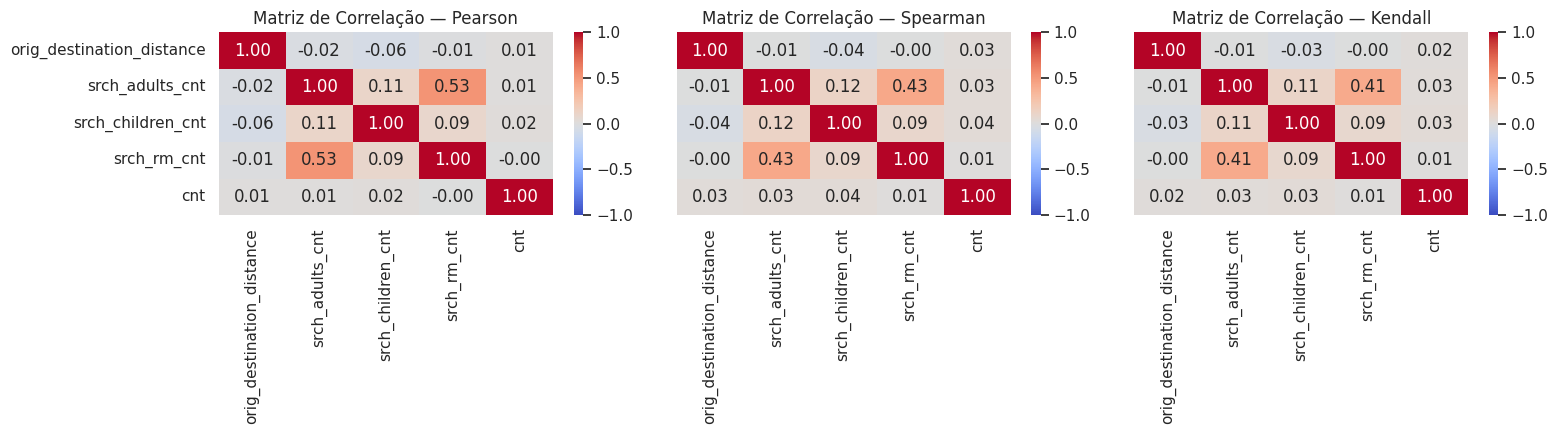

In [33]:
VARS_QUANT_CORR = ["orig_destination_distance", "srch_adults_cnt", "srch_children_cnt", "srch_rm_cnt", "cnt"]

corr_pearson = df[VARS_QUANT_CORR].corr(method="pearson")
corr_spearman = df[VARS_QUANT_CORR].corr(method="spearman")
corr_kendall = df[VARS_QUANT_CORR].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

**Discussão:** de modo geral as correlações são **fracas** — nada surpreendente pra variáveis de busca que dependem mais do perfil de cada viajante do que umas das outras. O par mais forte é `srch_adults_cnt` x `srch_rm_cnt` (Spearman ≈ 0,43, moderada): faz sentido de domínio — mais adultos na busca tende a pedir mais quartos. Pearson e Spearman ficam bem próximos entre si na maioria dos pares, o que sugere que não há uma relação não-linear forte escondida sendo perdida pelo Pearson.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `srch_adults_cnt` x `srch_rm_cnt`: é o par com maior |correlação| na tabela acima **e** tem justificativa de domínio óbvia (mais pessoas, mais quartos) — os dois critérios convergem no mesmo par.

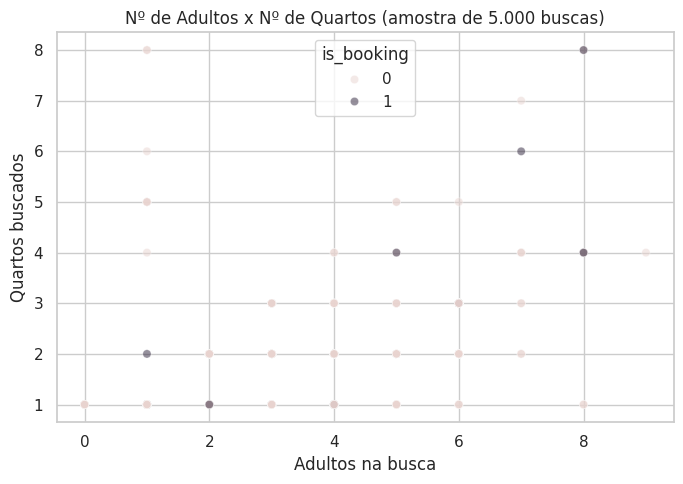

In [34]:
amostra = df.sample(5000, random_state=42)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=amostra, x="srch_adults_cnt", y="srch_rm_cnt", hue="is_booking",
                palette={0: COR_CONTEXTO, 1: COR_DESTAQUE}, alpha=0.5)
plt.title("Nº de Adultos x Nº de Quartos (amostra de 5.000 buscas)")
plt.xlabel("Adultos na busca")
plt.ylabel("Quartos buscados")
plt.tight_layout()
plt.show()

**Discussão:** a tendência crescente é visível, mas com bastante dispersão — grupos grandes de adultos (6+) nem sempre pedem mais de 1-2 quartos (podem estar dividindo o mesmo quarto). Não dá pra ver um padrão claro de separação entre buscas que viraram reserva (roxo) e as que não viraram (rosa) só nesse par — o que já sugere que essas duas variáveis sozinhas não são grandes preditoras de conversão.

#### Quantitativa x Qualitativa: Comparando Grupos

Nenhuma das nossas quantitativas passou no Shapiro-Wilk (Seção 3), então os testes não-paramétricos (**Mann-Whitney U**, **Kruskal-Wallis**) são os que deveríamos reportar como principais — calculamos os paramétricos (T-test, ANOVA) só como contraste.

In [35]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao_reservou = df.loc[df["is_booking"] == 0, col].dropna()
    grupo_reservou = df.loc[df["is_booking"] == 1, col].dropna()

    stat_t, p_t = stats.ttest_ind(grupo_nao_reservou, grupo_reservou, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao_reservou, grupo_reservou)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
orig_destination_distance,0.00000,0.00000,True
srch_children_cnt,0.00000,0.00000,True
srch_rm_cnt,0.00407,0.00095,True


**Discussão:** os dois testes concordam nas três variáveis. Vale uma ressalva sobre `orig_destination_distance`: como sua ausência está fortemente ligada a `posa_continent` (Seção 2), esse teste compara implicitamente uma mistura de continentes diferente em cada grupo — o resultado é real, mas não isola "efeito de reservar" de "efeito de vir de tal continente".

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis:* comparamos `cnt` (nº de eventos de busca semelhantes registrados) entre os 5 `posa_continent`.

ANOVA          — cnt entre posa_continent: estatística=18.270, p-valor=5.1346e-15
Kruskal-Wallis — cnt entre posa_continent: estatística=88.032, p-valor=3.4476e-18


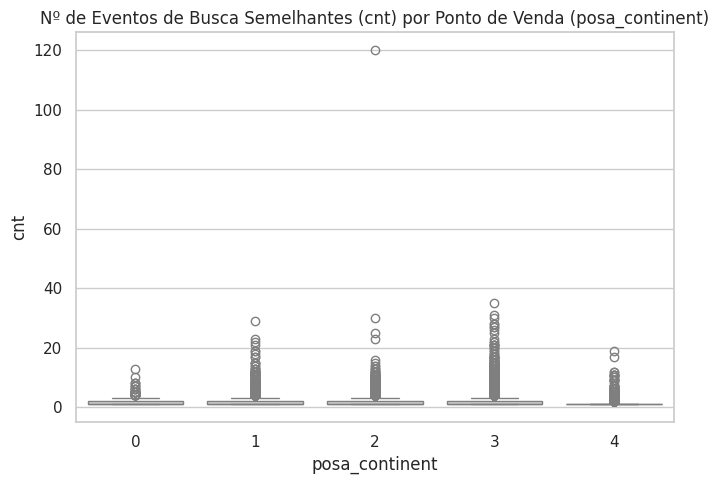

In [36]:
grupos_continente = [grupo["cnt"].values for _, grupo in df.groupby("posa_continent")]

stat_anova, p_anova = stats.f_oneway(*grupos_continente)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_continente)          # não-paramétrico

print(f"ANOVA          — cnt entre posa_continent: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — cnt entre posa_continent: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="posa_continent", y="cnt", color=COR_NEUTRA)
plt.title("Nº de Eventos de Busca Semelhantes (cnt) por Ponto de Venda (posa_continent)")
plt.tight_layout()
plt.show()

**Discussão:** os dois testes concordam em rejeitar a hipótese de que `cnt` tem a mesma distribuição nos 5 continentes — como já era esperado pelo Kruskal-Wallis (nosso resultado principal, já que `cnt` também não é normal), existe diferença entre pelo menos um par de continentes.

#### Qualitativa x Qualitativa

`posa_continent` (5 categorias) x `is_booking` — mesmo papel que `thal` x `doenca_cardiaca` no exemplo da aula.

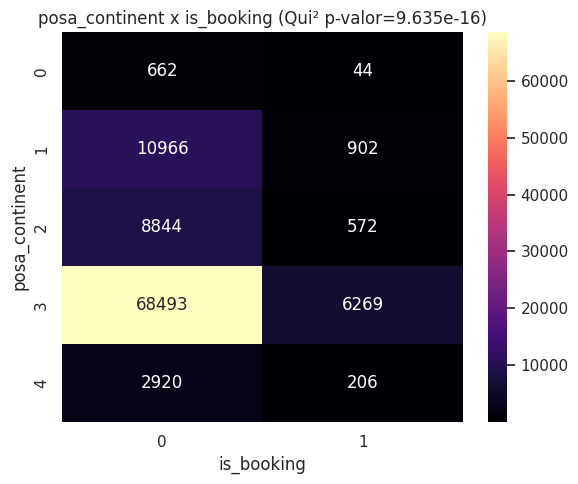

In [37]:
contingencia_continente = pd.crosstab(df["posa_continent"], df["is_booking"])
chi2_cont, p_cont, gl_cont, esperado_cont = stats.chi2_contingency(contingencia_continente)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_continente, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"posa_continent x is_booking (Qui² p-valor={p_cont:.4g})")
plt.tight_layout()
plt.show()

**Discussão:** o p-valor (≈ 7×10⁻¹⁶) indica associação estatisticamente significativa entre ponto de venda e conversão em reserva. A taxa de reserva varia de 6,1% (continente 2) a 8,4% (continente 3) — estatisticamente real (N grande), mas uma diferença de poucos pontos percentuais, então o **tamanho prático** do efeito é modesto.

#### Paridade entre segmentos (equivalente à checagem de *fairness* da aula)

O dataset de viagens não tem atributos demográficos sensíveis (sexo, idade) como o Heart Disease — então aplicamos a mesma lógica a **segmentos de comportamento**: será que a taxa de conversão (`is_booking`) muda entre quem busca pelo celular (`is_mobile`) e quem busca com/sem pacote (`is_package`)? Isso não é uma checagem de fairness no sentido de atributo protegido, mas usa exatamente a mesma técnica (proporções + Qui-Quadrado) pra comparar subgrupos.

In [38]:
for atributo in ["is_mobile", "is_package"]:
    contingencia = pd.crosstab(df[atributo], df["is_booking"])
    chi2_seg, p_seg, gl_seg, esperado_seg = stats.chi2_contingency(contingencia)
    taxa = df.groupby(atributo)["is_booking"].mean()
    print(f"--- {atributo} x is_booking --- chi2={chi2_seg:.2f}  p={p_seg:.4g}")
    print((taxa * 100).round(2).astype(str) + "%")
    print()

--- is_mobile x is_booking --- chi2=81.11  p=2.138e-19
is_mobile
0    8.31%
1    6.03%
Name: is_booking, dtype: object

--- is_package x is_booking --- chi2=661.89  p=5.806e-146
is_package
0    9.27%
1    4.16%
Name: is_booking, dtype: object



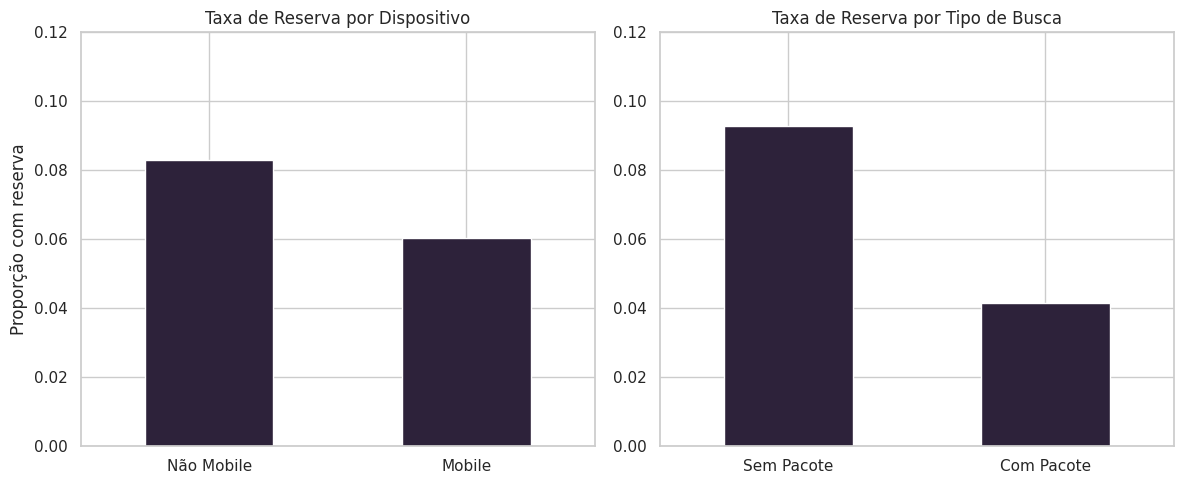

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_mobile = df.groupby("is_mobile")["is_booking"].mean()
prop_mobile.index = ["Não Mobile", "Mobile"]
prop_mobile.plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Taxa de Reserva por Dispositivo")
axes[0].set_ylabel("Proporção com reserva")
axes[0].set_ylim(0, 0.12)
axes[0].tick_params(axis="x", rotation=0)

prop_pacote = df.groupby("is_package")["is_booking"].mean()
prop_pacote.index = ["Sem Pacote", "Com Pacote"]
prop_pacote.plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Taxa de Reserva por Tipo de Busca")
axes[1].set_ylim(0, 0.12)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Discussão:** as duas diferenças são estatisticamente significativas (p < 0,001) e, dessa vez, também grandes na prática: buscas **Mobile** convertem menos (6,0% vs. 8,3% em Não Mobile) — padrão comum em e-commerce, onde a intenção de compra no celular costuma ser mais exploratória. O efeito de `is_package` é ainda maior: buscas **com pacote** convertem bem menos (4,2% vs. 9,3% sem pacote) — possivelmente porque pacotes têm um funil de decisão mais longo (envolvem voo + hotel), ou porque `is_booking` aqui capture só a etapa de hotel, não o pacote completo. Vale registrar como uma pergunta em aberto, não uma conclusão fechada — não temos como confirmar sem mais contexto do negócio.

#### Outliers bivariados

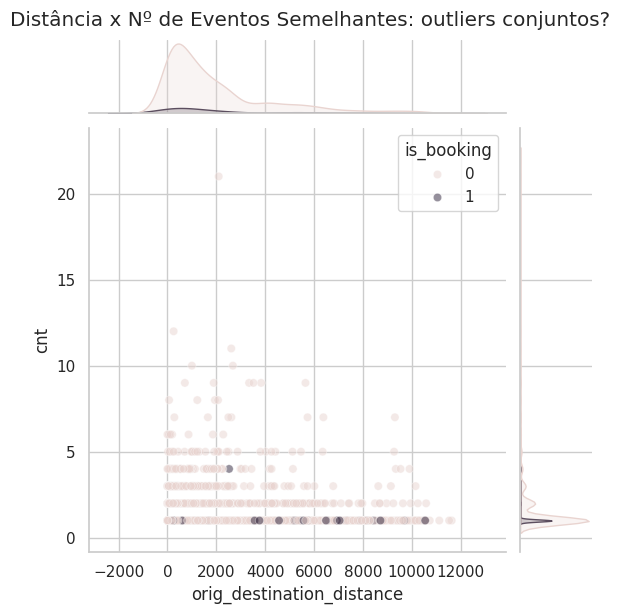

In [40]:
amostra_joint = df.sample(4000, random_state=42)

sns.jointplot(data=amostra_joint, x="orig_destination_distance", y="cnt", hue="is_booking",
              palette={0: COR_CONTEXTO, 1: COR_DESTAQUE}, alpha=0.5, height=6)
plt.suptitle("Distância x Nº de Eventos Semelhantes: outliers conjuntos?", y=1.02)
plt.show()

**Discussão:** a grande maioria das buscas tem `cnt` baixo (poucos eventos semelhantes) em qualquer distância — os poucos pontos com `cnt` alto (10+) não se destacavam nos histogramas univariados de `orig_destination_distance` (Seção 3), mas aqui aparecem como uma combinação pouco comum: muitas buscas semelhantes *e* distância específica, possivelmente o comportamento de um usuário comparando bastante antes de decidir.

### Análise Multivariada

##### Matriz de Correlação

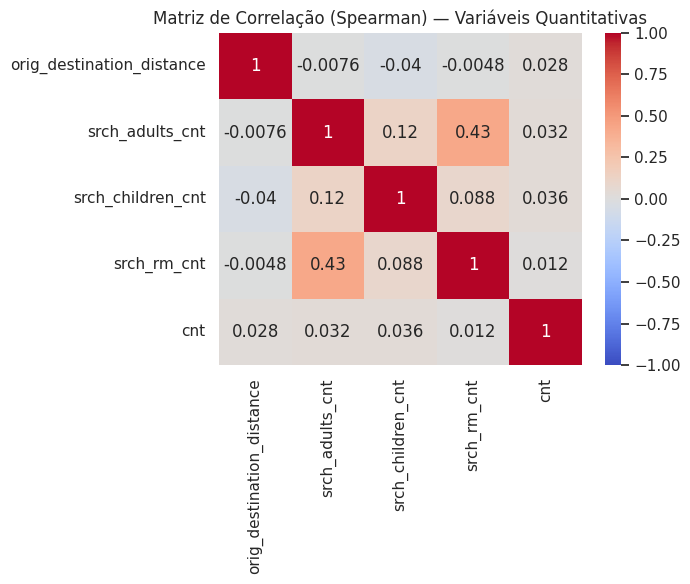

In [41]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT_CORR].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**

* |r| < 0.3 ~ fraca
* 0.3 < |r| < 0.7 ~ moderada
* |r| > 0.7 ~ forte

Só o par `srch_adults_cnt` x `srch_rm_cnt` chega perto de "moderada" (≈0,43); todo o resto é fraco — não há sinal de redundância entre variáveis aqui (o oposto do que se costuma temer em multicolinearidade).

##### Correlograma

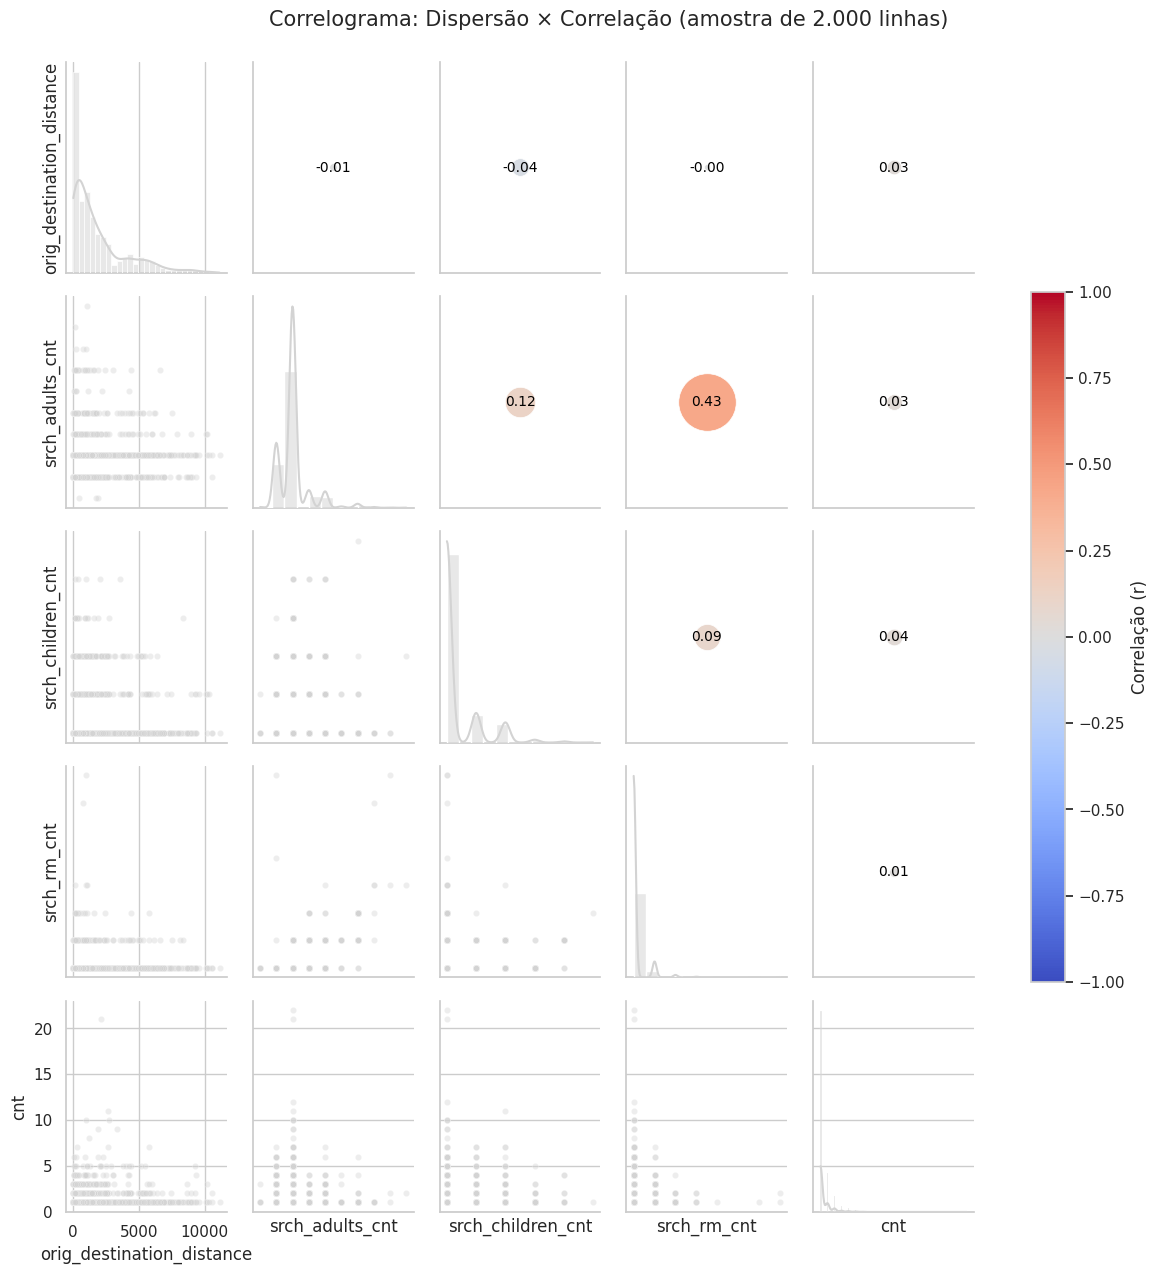

In [42]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# Correlação (Spearman) calculada com a base inteira -- a amostra abaixo é só
# para o scatter (performance/legibilidade), os círculos usam o valor "de verdade".
corr_completa = df[VARS_QUANT_CORR].corr(method="spearman")

def circulo_correlacao(x, y, **kwargs):
    r = corr_completa.loc[x.name, y.name]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# Amostra de 2.000 linhas: com 100.000 pontos o scatter fica ilegível (overplotting) e lento
amostra_corr = df[VARS_QUANT_CORR].sample(2000, random_state=42)

g = sns.PairGrid(amostra_corr, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.4, s=20)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação (amostra de 2.000 linhas)", y=1.02, fontsize=15)
plt.show()

**Discussão:** o correlograma confirma visualmente a matriz numérica — a única nuvem de pontos com alguma estrutura é `srch_adults_cnt` x `srch_rm_cnt`; as demais parecem "blobs" sem padrão, coerente com correlações próximas de zero. Usamos uma amostra de 2.000 linhas aqui só por performance/legibilidade do gráfico — as correlações usadas no círculo são as mesmas calculadas com a base inteira, não recalculadas na amostra.

## Síntese Final

### Principais Conclusões

1. **Os dados ausentes têm dois mecanismos bem diferentes, e isso mudou o tratamento.** `srch_ci`/`srch_co` (0,12%, sempre juntas) parecem MCAR/MAR de baixo impacto e foram removidas sem problema. Já `orig_destination_distance` (36,1%) está fortemente associada a `posa_continent` (96,5% ausente no continente 2 vs. 22,4% no continente 3, χ² ≈ 28.161) — um padrão MAR forte demais pra ignorar, e grande demais pra simplesmente descartar as linhas. A decisão de manter os ausentes (com uma flag indicadora) em vez de remover ou imputar evitou introduzir viés geográfico no restante da análise.

2. **As três variáveis quantitativas centrais são fortemente não-normais**, com assimetria alta (1,6 a 6,8) e Shapiro-Wilk rejeitando normalidade mesmo depois do tratamento — por isso os testes não-paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) foram usados como resultado principal ao longo de todo o notebook, não só como formalidade.

3. **A regra do IQR para outliers não funciona bem em variáveis discretas e concentradas.** `srch_children_cnt` e `srch_rm_cnt` tiveram 21.253 e 8.327 "outliers" respectivamente, só porque Q1=Q3 nessas colunas (a maioria dos valores é 0 ou 1) — um artefato do método, não uma anomalia real nos dados. Vale como lição geral: IQR pressupõe alguma dispersão real no meio da distribuição.

4. **A correlação entre as variáveis quantitativas de busca é fraca em geral** (a maioria |r| < 0,1), com uma exceção moderada: `srch_adults_cnt` x `srch_rm_cnt` (Spearman ≈ 0,43) — mais adultos, mais quartos, a única relação com alguma força e também a única com justificativa de domínio direta.

5. **A taxa de conversão em reserva (`is_booking`, 8% no geral) varia de forma real entre segmentos**: cai para 6,0% em buscas Mobile (vs. 8,3% fora do Mobile) e para 4,2% em buscas com pacote (vs. 9,3% sem pacote) — as duas diferenças são estatisticamente significativas *e* grandes o suficiente pra importar na prática, ao contrário da diferença por `posa_continent` (significativa, mas só de 6,1% a 8,4% — efeito estatístico real, porém pequeno).

### Declaração de Uso de IA

Declaração de IA:
Declaro que usei IA (Claude) a fim de pesquisas e para uma reescrita dos textos de forma a deixar mais proficional